# ML Assignment 2 - Email spam classification with K-Nearest Neighbors and SVM

**Problem statement:** classify emails as *Not Spam* (normal state, 0) or *Spam* (abnormal state, 1) from word-count features using KNN (k=7) and a Support Vector Machine, then analyse and compare accuracy, confusion matrix, precision and recall.

**Libraries used:** pandas, numpy (data), seaborn/matplotlib (confusion matrix plots), scikit-learn (scaling, KNN, SVC, metrics).

**Driver:** the Kaggle email dataset is not available offline, so word-count data in the same format (`Email No.`, word counts, `Prediction`) is generated with a fixed seed. To use the real file set `CSV_PATH = "emails.csv"`. No input is taken at runtime.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import scale
from sklearn.svm import SVC

CSV_PATH = None  # e.g. "emails.csv"

## 1. Load and prepare the data

In [2]:
def make_data(n=1500, words=100, seed=0):
    rng = np.random.default_rng(seed)
    label = (rng.random(n) < 0.3).astype(int)  # about 30 % spam
    rates = np.full((n, words), 0.6)
    rates[label == 1, :20] = 1.0   # the first 20 "words" are mildly more frequent in spam
    rates[label == 0, 20:40] = 0.9  # the next 20 are slightly more typical of normal mail
    df = pd.DataFrame(rng.poisson(rates), columns=[f"word{i}" for i in range(words)])
    df.insert(0, "Email No.", [f"Email {i + 1}" for i in range(n)])
    df["Prediction"] = label
    return df


df = pd.read_csv(CSV_PATH) if CSV_PATH else make_data()
df = df.dropna().drop(columns=["Email No."])
print(f"Emails: {len(df)}, features: {df.shape[1] - 1}, spam share: {df['Prediction'].mean():.1%}")

X, y = scale(df.drop(columns="Prediction")), df["Prediction"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

Emails: 1500, features: 100, spam share: 28.9%


## 2. K-Nearest Neighbors (k = 7)

In [3]:
knn_pred = KNeighborsClassifier(n_neighbors=7).fit(X_train, y_train).predict(X_test)
print("KNN accuracy:", round(accuracy_score(y_test, knn_pred), 3))
print("Confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(y_test, knn_pred))

KNN accuracy: 0.789
Confusion matrix [[TN FP] [FN TP]]:
 [[313  13]
 [ 82  42]]


## 3. Support Vector Machine (C = 1)

In [4]:
svm_pred = SVC(C=1).fit(X_train, y_train).predict(X_test)
print("SVM accuracy:", round(accuracy_score(y_test, svm_pred), 3))
print("Confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(y_test, svm_pred))

SVM accuracy: 0.898
Confusion matrix [[TN FP] [FN TP]]:
 [[318   8]
 [ 38  86]]


## 4. Compare the two models

model     accuracy  precision  recall
KNN          0.789      0.764   0.339
SVM          0.898      0.915   0.694


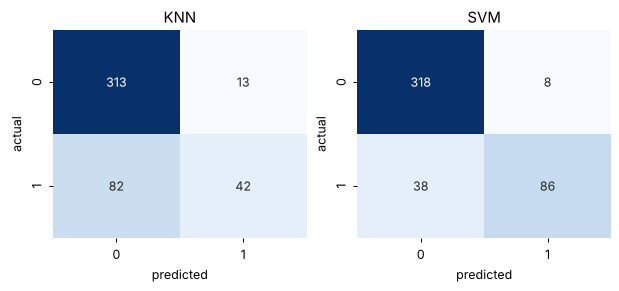

In [5]:
print(f"{'model':<8}{'accuracy':>10}{'precision':>11}{'recall':>8}")
for name, pred in (("KNN", knn_pred), ("SVM", svm_pred)):
    print(f"{name:<8}{accuracy_score(y_test, pred):>10.3f}{precision_score(y_test, pred):>11.3f}{recall_score(y_test, pred):>8.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, (name, pred) in zip(axes, (("KNN", knn_pred), ("SVM", svm_pred))):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")

**Conclusion:** for spam filtering, high *recall* means few spam mails slip through and high *precision* means few normal mails are wrongly blocked. Use the table above to decide which model performs better on this data.